# Project Module 3: Implementation
**Community Detection**

*2MBS80 - Complex Networks*

Submission by **Project Group 6** with the following group members:
- Huy Hong (1935569)
- Andrei Sirbu
- Tjerk Williams (2282623)

### Table of Contents
1. [Imports](#imports)
2. [Problem 1](#problem-1)
    - [Estimating the number of communities in a graph](#procedure)
    - [Procedure testing](#testing)
    - [Procedure evaluation](#procedure-eval)
3. [Problem 2](#problem-2)
    - [Choice of real-life network](#rl-network)
    - [Spectral clustering](#sc)
    - [Louvain's algorithm](#louvain)
    - [Partition agreement measure](#measure)
    - [Evaluation](#measure-eval)

## Imports <a name="imports" id="imports"></a>
These are the packages and prerequisites required for running the code.

In [25]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import mmread

SEED = 2026

## Problem 1 <a name="problem-1" id="problem-1"></a>
Design a procedure to estimate the number of communities in a graph, explaining
what feature of the graph it uses and why.

Test your procedure on stochastic block models with different numbers of communities and different levels of separation. Use repeated samples to account for randomness, and present your estimates against the planted numbers in a clear figure. When does your procedure succeed, and where does it fail? Investigate one weakness of your approach.

### Estimating the number of communities in a graph <a name="procedure" id="procedure"></a>

Add explanation

In [26]:
def find_community(G, seed, gamma = 1.0):
    """
    Checks each vertex and adds the neighbor with the largest modularity gain, where we stop once the best gain is no longer positive.

    Parameters:
    :G: Graph
    :seed: Random seed
    :gamma: Resolution parameter (default is 1)
    :return: Community
    """
    C = {seed} # Initialize community
    d = dict(G.degree()) # Keep track of vertex degrees

    edges_to_C = {u: 1 for u in G.neighbors(seed)}
    next_v = set(edges_to_C) # Set of edges to a vertex's neighbors
    sum_d_C = d[seed]

    # While there is an untraversed edge from a vertex to its neighbor, we first compute the vertex with the highest modularity gain
    while next_v:
        best_v = None
        best_gain = 0.0

        for v in next_v:
            mod_gain = edges_to_C[v] - gamma * d[v] * sum_d_C / (2 * G.number_of_edges())

            # Update the best modularity gain and the vertex resulting in this gain, if a higher value is found.
            if mod_gain > best_gain:
                best_gain = mod_gain
                best_v = v

        # There exists no vertex with a better modularity gain value.
        if best_v is None:
            break

        C.add(best_v) # Add the vertex with the highest modularity gain in the community as the 'centroid'
        sum_d_C += d[best_v]
        next_v.discard(best_v) # Remove the vertex with the highest modularity gain after it has been added to a community

        # Continuing checking the modularity for the neighbors of the 'best vertex'
        for u in G.neighbors(best_v):
            if u in C:
                continue
            if u in edges_to_C:
                edges_to_C[u] += 1
            else:
                edges_to_C[u] = 1
            next_v.add(u)

    return C

Add explanation

In [ ]:
def community_number_estimator(G, gamma = 1.0, min_size = 2):
    """
    Expand a community from the highest-degree remaining vertex, remove it and continue until all edges have been checked.

    Parameters:
    :G: Graph
    :gamma: Resolution parameter
    :min_com_size: Minimum community size
    :return: Number of communities in a graph
    """
    H = G.copy()
    community_count = 0

    while H.number_of_edges() > 0:
        seed = max(H.nodes(), key = lambda v: H.degree(v))

        # Vertex is isolated
        if H.degree(seed) == 0: 
            break

        # Form a community and add it to the count
        C = find_community(H, seed, gamma)
        if len(C) >= min_size:
            community_count += 1

        # Remove community from graph
        H.remove_nodes_from(C) 

    return community_count

In [28]:
def estimate_k_eigengap(G, k_max=10):
    """
    Estimate K as the location of the largest gap in the first k_max+1
    eigenvalues of the normalized Laplacian L = I - D^{-1/2} A D^{-1/2}.
    For K well-separated communities, lambda_1 ~ ... ~ lambda_K ~ 0 and
    lambda_{K+1} is separated by a large gap.
    """
    A = nx.to_numpy_array(G)
    d = A.sum(axis=1)
    d_inv_sqrt = np.where(d > 0, 1.0 / np.sqrt(d), 0.0)
    L = np.eye(len(d)) - d_inv_sqrt[:, None] * A * d_inv_sqrt[None, :]
    vals = np.sort(np.linalg.eigvalsh(L))

    k = min(k_max, len(vals) - 1)
    gaps = np.diff(vals[:k + 1])
    return int(np.argmax(gaps)) + 1

# CAN BE REMOVED IF NEEDED, THIS IS FOR COMPARISON WITH THE CORRECT METHOD

### Procedure testing <a name="testing" id="testing"></a>
Add explanation

In [29]:
def SBM_K(K_values, n, q_in, q_out, n_samples):
    """ 
    Generate an SBM for different values of the number of communities K

    Parameters:
    :K_values: Number of communities generated by the SBM
    :n: Number of vertices
    :q_in: Probability that two nodes are in the same community
    :q_out: Probability that two nodes are in different communities
    :n_samples: Number of samples for the SBM
    :return: The number of esitmated communities
    """
    results = {K: {"local": [], "eigengap": []} for K in K_values}

    for K in K_values:
        sizes = [n // K] * K
        sizes[0] += n - sum(sizes)

        # Generate the SBM matrix
        Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

        for s in range(n_samples):
            G = nx.stochastic_block_model(sizes, Q, seed = SEED + s)
            results[K]["local"].append(community_number_estimator(G))
            results[K]["eigengap"].append(estimate_k_eigengap(G))

    return results


K_values = [2, 3, 4, 5, 6]
n = 300
q_in = 0.3
q_out = 0.02
n_samples = 10

res_K = SBM_K(K_values, n, q_in, q_out, n_samples)

print("Number of communities | BFS method (mean ± std) | Eigengap method (mean ± std)")
for K in K_values:
    lm = np.mean(res_K[K]["local"]);  ls = np.std(res_K[K]["local"])
    em = np.mean(res_K[K]["eigengap"]); es = np.std(res_K[K]["eigengap"])
    print(f"    {K:2d}    |     {lm:4.1f} ± {ls:4.2f}      |     {em:4.1f} ± {es:4.2f}")

Number of communities | BFS method (mean ± std) | Eigengap method (mean ± std)
     2    |      7.0 ± 0.45      |      2.0 ± 0.00
     3    |      7.3 ± 0.64      |      3.0 ± 0.00
     4    |      7.9 ± 0.30      |      4.0 ± 0.00
     5    |      8.4 ± 0.49      |      5.0 ± 0.00
     6    |      8.7 ± 0.64      |      6.0 ± 0.00


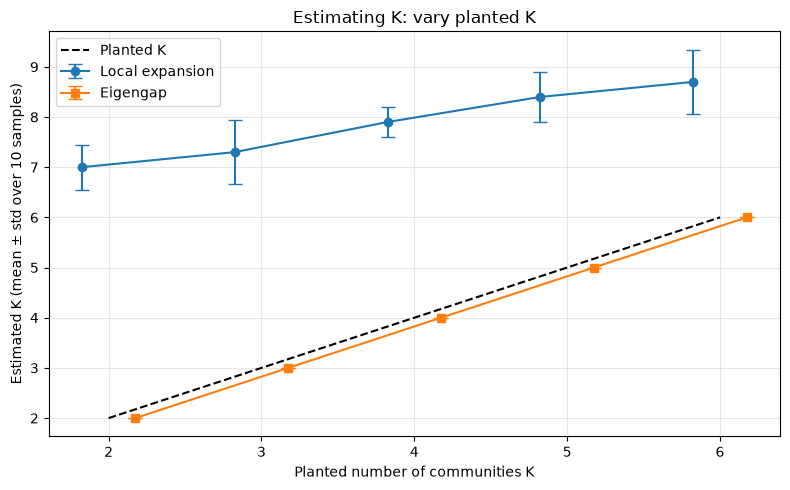

In [30]:
# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(K_values))
w = 0.35

ax.errorbar(x - w/2,
            [np.mean(res_K[K]["local"])    for K in K_values],
            yerr=[np.std(res_K[K]["local"]) for K in K_values],
            fmt="o-", capsize=5, label="Local expansion")
ax.errorbar(x + w/2,
            [np.mean(res_K[K]["eigengap"])    for K in K_values],
            yerr=[np.std(res_K[K]["eigengap"]) for K in K_values],
            fmt="s-", capsize=5, label="Eigengap")
ax.plot(x, K_values, "k--", label="Planted K")

ax.set_xticks(x)
ax.set_xticklabels(K_values)
ax.set_xlabel("Planted number of communities K")
ax.set_ylabel("Estimated K (mean ± std over 10 samples)")
ax.set_title("Estimating K: vary planted K")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Add explanation

In [31]:
def SBM_separation(q_out_values, K, n, q_in, n_samples):
    """ 
    Generate an SBM for different values of the probability q_out, which is the probability that any two nodes are in different communities

    Parameters:
    :q_out_values: Probabilities that two nodes are in different communities
    :K: Number of communities generated by the SBM
    :n: Number of vertices
    :q_in: Probability that two nodes are in the same community
    :n_samples: Number of samples for the SBM
    :return: The number of esitmated communities
    """
    results = {q: {"local": [], "eigengap": []} for q in q_out_values}
    sizes = [n // K] * K
    sizes[0] += n - sum(sizes)

    for q_out in q_out_values:
        Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

        for s in range(n_samples):
            G = nx.stochastic_block_model(sizes, Q, seed=SEED + s)
            results[q_out]["local"].append(community_number_estimator(G))
            results[q_out]["eigengap"].append(estimate_k_eigengap(G))
            
    return results


q_out_values = [0.005, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
K = 3
n = 300
q_in = 0.3
n_samples = 10

res_sep = SBM_separation(q_out_values, K, n, q_in, n_samples)

print("q_out | BFS method (mean ± std) | Eigengap method (mean ± std)")

for q in q_out_values:
    lm = np.mean(res_sep[q]["local"]);  ls = np.std(res_sep[q]["local"])
    em = np.mean(res_sep[q]["eigengap"]); es = np.std(res_sep[q]["eigengap"])
    print(f"{q:5.3f} |     {lm:4.1f} ± {ls:4.2f}      |     {em:4.1f} ± {es:4.2f}")

q_out | BFS method (mean ± std) | Eigengap method (mean ± std)
0.005 |      7.4 ± 0.49      |      3.0 ± 0.00
0.010 |      7.4 ± 0.49      |      3.0 ± 0.00
0.020 |      7.3 ± 0.64      |      3.0 ± 0.00
0.050 |      7.2 ± 0.40      |      2.8 ± 0.60
0.100 |      7.6 ± 0.49      |      1.0 ± 0.00
0.150 |      7.2 ± 0.40      |      1.0 ± 0.00
0.200 |      7.3 ± 0.46      |      1.0 ± 0.00


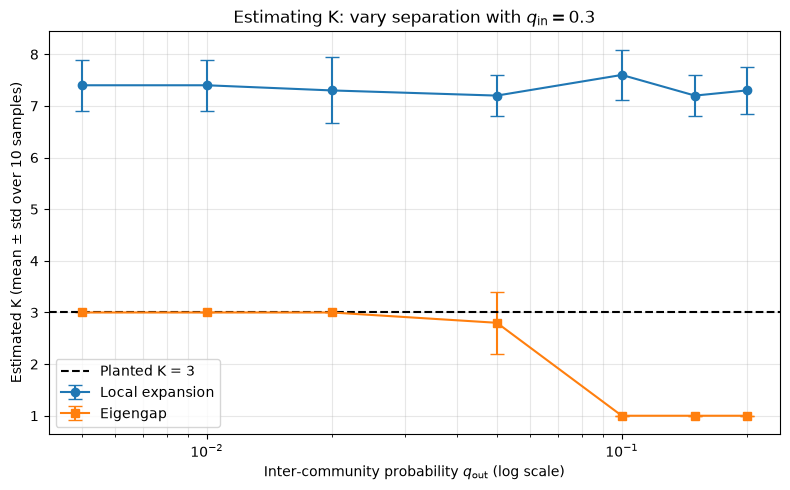

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(q_out_values,
            [np.mean(res_sep[q]["local"]) for q in q_out_values],
            yerr=[np.std(res_sep[q]["local"]) for q in q_out_values],
            fmt="o-", capsize=5, label="Local expansion")
ax.errorbar(q_out_values,
            [np.mean(res_sep[q]["eigengap"]) for q in q_out_values],
            yerr=[np.std(res_sep[q]["eigengap"]) for q in q_out_values],
            fmt="s-", capsize=5, label="Eigengap")
ax.axhline(3, color="k", ls="--", label="Planted K = 3")

ax.set_xscale("log")
ax.set_xlabel(r"Inter-community probability $q_{\text{out}}$ (log scale)")
ax.set_ylabel("Estimated K (mean ± std over 10 samples)")
ax.set_title(r"Estimating K: vary separation with $q_{\text{in}} = 0.3$")
ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

### Procedure evaluation <a name="procedure-eval" id="procedure-eval"></a>

A main weakness is that this method is particulary sensitive to merging of small communities, and so we demonstrate this effect for different values of the resolution parameter $\gamma$ below:

In [33]:
def SBM_gamma(gamma_values, K, n, q_in, q_out, n_samples):
    """ 
    Generate an SBM for different values of the probability q_out, which is the probability that any two nodes are in different communities

    Parameters:
    :gamma_values: Resolution parameter values
    :K: Number of communities generated by the SBM
    :n: Number of vertices
    :q_in: Probability that two nodes are in the same community
    :n_samples: Number of samples for the SBM
    :return: The number of esitmated communities
    """
    sizes = [n // K] * K
    sizes[0] += n - sum(sizes)
    Q = [[q_in if i == j else q_out for j in range(K)] for i in range(K)]

    results = {g: [] for g in gamma_values}
    
    for s in range(n_samples):
        G = nx.stochastic_block_model(sizes, Q, seed = SEED + s)

        for g in gamma_values:
            results[g].append(community_number_estimator(G, gamma = g))

    return results


gamma_values = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]

K = 3
n = 300
q_in = 0.3
q_out = 0.02
n_samples = 10

res_gamma = SBM_gamma(gamma_values, K, n, q_in, q_out, n_samples)

print("gamma | Estimated number of communities K (mean ± std)")
for g in gamma_values:
    m = np.mean(res_gamma[g]); s = np.std(res_gamma[g])
    print(f"{g:5.1f} | {m:4.1f} ± {s:4.2f}")

KeyboardInterrupt: 

In [ ]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.errorbar(gamma_values,
            [np.mean(res_gamma[g]) for g in gamma_values],
            yerr=[np.std(res_gamma[g]) for g in gamma_values],
            fmt = "o-", capsize = 5)
ax.axhline(3, color = "k", ls = "--", label = "Num. communities K = 3")

ax.set_xscale("log")
ax.set_xlabel(r"Resolution parameter (log scale)")
ax.set_ylabel("Estimated K (mean ± std over 10 samples)")
ax.set_title(r"Weakness: sensitivity to the resolution parameter")
ax.legend()
ax.grid(alpha = 0.3, which = "both")
plt.tight_layout()
plt.show()

## Problem 2 <a name="problem-2" id="problem-2"></a>
Choose a real-life network online that you expect to have communities, and explain what they might represent.

Apply spectral clustering using your estimated number of communities, and compare the resulting partition with Louvain. Report the number and sizes of the communities found by each method, and plot the network coloured by each partition.

Choose and motivate a measure of agreement between the two partitions. Interpret their agreement or disagreement using the context of the network and any available vertex metadata.

### Choice of real-life network <a name="rl-network" id="rl-network"></a>

For the real life network, we chose a sparce facebook network. Nodes represent users and edges represent friendships between users.
n = 18.448
|E| = 973.9K


In [ ]:
# Read the .mtx file as a sparse matrix

def graph_reader(path):
    """
    Converts edges from a .mtx file into a usable graph
    """
    matrix = mmread(path)
    return nx.Graph(matrix)

fb = graph_reader('facebook.mtx')

C:\Users\Admin\AppData\Local\Temp\ipykernel_44860\550654477.py:7: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  matrix = mmread(path)


### Spectral clustering <a name="sc" id="sc"></a>

### Louvain's algorithm <a name="louvain" id="louvain"></a>

### Partition agreement measure <a name="measure" id="measure"></a>

### Measure evaluation <a name="measure-eval" id="measure-eval"></a>